# pyATM: the CASA `atmosphere` tool

`pyatm.casa.atmosphere` reproduces `casatools.atmosphere`: same method names, defaults, quantity
inputs (numbers, strings like `"5 km"`, or `{'value': ..., 'unit': ...}`) and outputs
(`{'value': numpy array, 'unit': str}`). Methods with output arguments in CASA return tuples here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyatm.casa import atmosphere, quantity

at = atmosphere()
print(at.getAtmVersion())
print(at.listAtmosphereTypes())

ATM-1_0_0
['1 - TROPICAL', '2 - MIDLATSUMMER', '3 - MIDLATWINTER', '4 - SUBARTSUMMER', '5 - SUBARTWINTER']


## Atmospheric profile

In [2]:
print(at.initAtmProfile(altitude=quantity(5059, "m"), temperature="270 K", pressure=quantity(560, "mbar"),
                        maxAltitude="48 km", humidity=20, dTem_dh=quantity(-5.6, "K/km"),
                        dP=quantity(10, "mbar"), dPm=1.2, h0=quantity(2, "km"), atmType=1))
print("Layers:", at.getNumLayers(), "| PWV:", at.getGroundWH2O())

BASIC ATMOSPHERIC PARAMETERS TO GENERATE REFERENCE ATMOSPHERIC PROFILE
  
Ground temperature T:         270 K
Ground pressure P:            560 mb
Relative humidity rh:         20 %
Scale height h0:              2 km
Pressure step dp:             10 mb
Altitude alti:                5059 m
Attitude top atm profile:     48 km
Pressure step factor:         1.2 
Tropospheric lapse rate:      -5.6 K/km
Atmospheric type:             TROPICAL
User-defined temperature profile: OFF

Built atmospheric profile with 27 layers.


Layers: 27 | PWV: {'value': array([1.57637308]), 'unit': 'mm'}


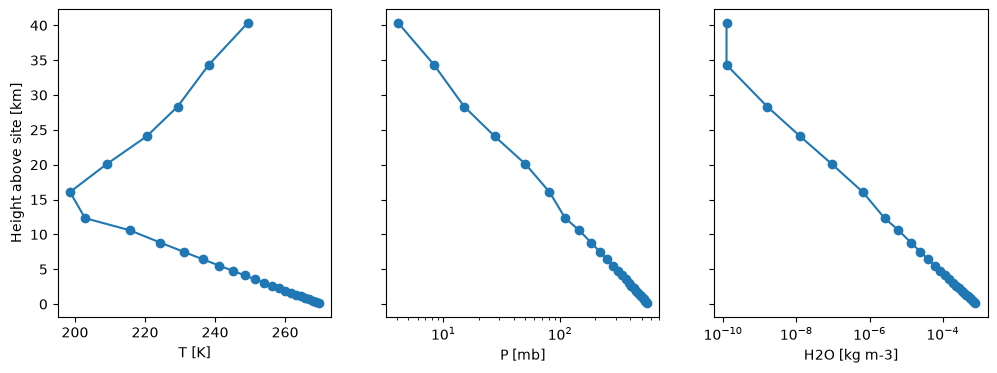

In [3]:
text, thickness, temperature, watermassdensity, water, pressure, O3, CO, N2O = at.getProfile()
height = np.cumsum(thickness["value"]) / 1e3
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
ax[0].plot(temperature["value"], height, "o-"); ax[0].set_xlabel(f"T [{temperature['unit']}]")
ax[0].set_ylabel("Height above site [km]")
ax[1].semilogx(pressure["value"], height, "o-"); ax[1].set_xlabel(f"P [{pressure['unit']}]")
ax[2].semilogx(watermassdensity["value"], height, "o-"); ax[2].set_xlabel(f"H2O [{watermassdensity['unit']}]")
plt.show()

## Spectral windows and opacities

spws: 2 channels: 1400 400
spw 0: {'value': array([50.25]), 'unit': 'GHz'} - {'value': array([749.75]), 'unit': 'GHz'} ref chan 699 {'value': array([399.75]), 'unit': 'GHz'}


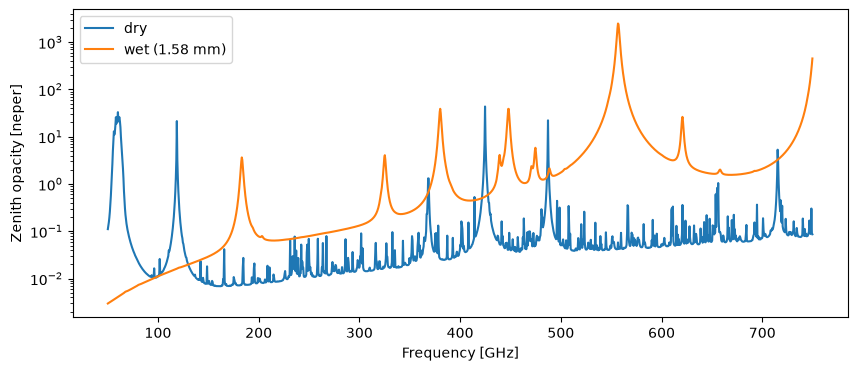

In [4]:
nchan = at.initSpectralWindow(nbands=1, fCenter=quantity(400, "GHz"), fWidth=quantity(700, "GHz"),
                              fRes=quantity(0.5, "GHz"))
nchan2 = at.addSpectralWindow(fCenter=quantity(183.31, "GHz"), fWidth=quantity(20, "GHz"), fRes=quantity(0.05, "GHz"))
print("spws:", at.getNumSpectralWindows(), "channels:", nchan, nchan2)
print("spw 0:", at.getMinFreq(0), "-", at.getMaxFreq(0), "ref chan", at.getRefChan(0), at.getRefFreq(0))

freq = np.array([at.getChanFreq(i, 0)["value"][0] for i in range(nchan)])
n, dry = at.getDryOpacitySpec(0)
n, wet = at.getWetOpacitySpec(0)
plt.figure(figsize=(10, 4))
plt.semilogy(freq, dry, label="dry")
plt.semilogy(freq, wet["value"], label=f"wet ({at.getUserWH2O()['value'][0]:.2f} {at.getUserWH2O()['unit']})")
plt.xlabel("Frequency [GHz]"); plt.ylabel("Zenith opacity [neper]"); plt.legend(); plt.show()

## Sky brightness for several water columns and air masses

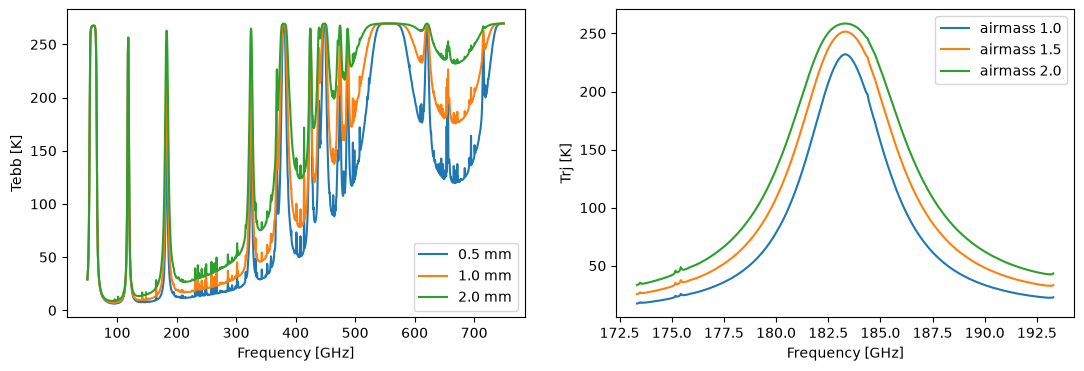

Average Tebb (spw 1, PWV 1 mm): {'value': array([81.64365117]), 'unit': 'K'}
Average Tebb (spw 1, PWV 2 mm): {'value': array([118.58870089]), 'unit': 'K'}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for pwv in (0.5, 1.0, 2.0):
    at.setUserWH2O(quantity(pwv, "mm"))
    n, tebb = at.getTebbSkySpec(spwid=0)
    ax[0].plot(freq, tebb["value"], label=f"{pwv} mm")
at.setUserWH2O(quantity(1.0, "mm"))
for am in (1.0, 1.5, 2.0):
    at.setAirMass(am)
    n, trj = at.getTrjSkySpec(spwid=1)
    f1 = [at.getChanFreq(i, 1)["value"][0] for i in range(n)]
    ax[1].plot(f1, trj["value"], label=f"airmass {am}")
at.setAirMass(1.0)
ax[0].set_xlabel("Frequency [GHz]"); ax[0].set_ylabel("Tebb [K]"); ax[0].legend()
ax[1].set_xlabel("Frequency [GHz]"); ax[1].set_ylabel("Trj [K]"); ax[1].legend(); plt.show()
print("Average Tebb (spw 1, PWV 1 mm):", at.getAverageTebbSky(spwid=1))
print("Average Tebb (spw 1, PWV 2 mm):", at.getAverageTebbSky(spwid=1, wh2o=quantity(2, "mm")))

## Phase delays and path lengths

In [6]:
# getChanNum is relative to the reference channel (as in ATM / CASA)
ch = at.getRefChan(0) + int(round(at.getChanNum(quantity(230, "GHz"), 0)))
print("Channel", ch, "at", at.getChanFreq(ch, 0))
for name in ("getNonDispersiveWetPathLength", "getDispersiveWetPathLength", "getNonDispersiveDryPathLength",
             "getNonDispersiveWetPhaseDelay", "getDispersivePhaseDelay"):
    print(f"{name:32s}", getattr(at, name)(ch, 0))

Channel 359 at {'value': array([229.75]), 'unit': 'GHz'}
getNonDispersiveWetPathLength    {'value': array([0.01105753]), 'unit': 'm'}
getDispersiveWetPathLength       {'value': array([0.0004948]), 'unit': 'm'}
getNonDispersiveDryPathLength    {'value': array([1.35039766]), 'unit': 'm'}
getNonDispersiveWetPhaseDelay    {'value': array([3050.67047221]), 'unit': 'deg'}
getDispersivePhaseDelay          {'value': array([86.59877076]), 'unit': 'deg'}


## Updating the profile and reading back the basic parameters

In [7]:
print(at.updateAtmProfile(altitude=quantity(5059, "m"), temperature=quantity(275, "K"), pressure=quantity(555, "mbar"),
                          humidity=40, dTem_dh=quantity(-5.6, "K/km"), h0=quantity(2, "km")))
text, altitude, temperature, pressure, maxAltitude, humidity, dTem_dh, dP, dPm, h0, atmType = at.getBasicAtmParms()
print(text)
print("PWV after update:", at.getGroundWH2O(), "| user PWV:", at.getUserWH2O())

UPDATED BASIC ATMOSPHERIC PARAMETERS TO GENERATE REFERENCE ATMOSPHERIC PROFILE
  
Ground temperature T:         275 K
Ground pressure P:            555 mb
Relative humidity rh:         40 %
Scale height h0:              2 km
Altitude alti:                5059 m
Tropospheric lapse rate:      -5.6 K/km


CURRENT ATMOSPHERIC PARAMETERS OF REFERENCE ATMOSPHERIC PROFILE
  
Ground temperature T:         275 K
Ground pressure P:            555 mbar
Relative humidity rh:         40 %
Scale height h0:              2 km
Pressure step dp:             10 mbar
Altitude alti:                5059 m
Attitude top atm profile      48 km
Pressure step factor          1.2 
Tropospheric lapse rate       -5.6 K/km
Atmospheric type:             TROPICAL

Atmospheric profile has 27 layers.


PWV after update: {'value': array([4.4674386]), 'unit': 'mm'} | user PWV: {'value': array([4.4674386]), 'unit': 'mm'}


In [8]:
at.done()

True